In [1]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 2.4 MB/s eta 0:00:0000:01


In [15]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, losses
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from imblearn.over_sampling import SMOTE
from scipy.io import wavfile
from scipy.signal import stft
import wfdb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd  # Added for PTB-XL CSV reading
import ast  # For parsing string lists in PTB-XL CSV
from tensorflow.keras import callbacks 

from sklearn.utils import class_weight
from tensorflow import keras
from tensorflow.keras import layers
import math

# Constants
IMG_HEIGHT = 128
IMG_WIDTH = 128
PATCH_SIZE = 16
EMBED_DIM = 256
NUM_HEADS = 8
FF_DIM = 512
DROPOUT_RATE = 0.5
NUM_CLASSES = 2
INPUT_ECG_SHAPE = (200, 12)  # 12 leads instead of 1
INPUT_PCG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 1)
BATCH_SIZE = 32
EPOCHS = 65
LEARNING_RATE = 3e-4

# Mamba block implementation (adapted for 1D ECG)
class MambaBlock(layers.Layer):
    def __init__(self, d_model, ssm_dim, dropout=0.5, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.ssm_dim = ssm_dim
        self.dropout = dropout
        self.dense1 = layers.Dense(ssm_dim, activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))
        self.dense2 = layers.Dense(d_model, kernel_regularizer=tf.keras.regularizers.l2(1e-4))
        self.gate_dense = layers.Dense(d_model, activation='sigmoid', kernel_regularizer=tf.keras.regularizers.l2(1e-4))  # Gating mechanism      
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        # SSM-like block: project, nonlinearity, project back, residual
        h = self.dense1(x)
        h = self.drop(h, training=training)
        h = self.dense2(h)
        h = self.drop(h, training=training)
        gate = self.gate_dense(x)  # Learn to select/weight features
        h = gate * h + (1 - gate) * x  # Selective residual connection
        return self.norm(h)

# --- PTB-XL ECG Data Loader (all leads) ---
def load_ptbxl_ecg_data(csv_path, records_path, num_samples=200):
    df = pd.read_csv(csv_path)
    available_records = []
    for root, dirs, files in os.walk(records_path):
        for file in files:
            if file.endswith('.hea'):
                base_id = file.split('_')[0]
                base_id = str(base_id).zfill(5)
                available_records.append(file.replace('.hea', ''))
    available_records = set(available_records)
    df = df[df['ecg_id'].astype(str).str.zfill(5).apply(lambda rid: any(rid in rec for rec in available_records))]
    X, Y = [], []
    exception_count = 0
    for idx, row in df.iterrows():
        rec_id = str(row['ecg_id']).zfill(5)
        rec_folder = rec_id[:2] + "000"
        rec_candidates = [rec for rec in available_records if rec.startswith(rec_id)]
        if not rec_candidates:
            if exception_count < 5:
                print(f"No matching record file for ecg_id {rec_id}")
            exception_count += 1
            continue
        rec_file = rec_candidates[0]
        rec_path = os.path.join(records_path, rec_folder, rec_file)
        try:
            signal, fields = wfdb.rdsamp(rec_path)
            # Use all 12 leads, shape: (time, 12)
            if signal.shape[0] < num_samples or signal.shape[1] < 12:
                continue
            # Take a random segment of num_samples
            start = np.random.randint(0, signal.shape[0] - num_samples + 1)
            segment = signal[start:start+num_samples, :12]  # shape (num_samples, 12)
            X.append(segment)
            scp_codes = ast.literal_eval(row['scp_codes']) if isinstance(row['scp_codes'], str) else row['scp_codes']
            label = 0 if 'NORM' in scp_codes else 1
            Y.append(label)
        except Exception as e:
            if exception_count < 5:
                print(f"Exception for record {rec_id}: {e}")
            exception_count += 1
            continue
    print(f"Loaded ECG samples: {len(X)}")
    print(f"Total exceptions: {exception_count}")
    return np.array(X), np.array(Y)


# Map labels to binary classes
def label_ecg(y):
    normal_classes = ['N', 'L', 'R']
    return 0 if y in normal_classes else 1

# Define Mamba-based model for ECG
def create_mamba_model(input_shape, d_model=128, ssm_dim=256, num_blocks=4, dropout=0.5):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(d_model, kernel_size=3, padding='same', activation='gelu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(inputs)
    for _ in range(num_blocks):
        x = MambaBlock(d_model, ssm_dim, dropout)(x)
    x = layers.GlobalAveragePooling1D()(x)
    # Add final classification layer for binary output
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return models.Model(inputs, outputs, name="ecg_mamba_model")

# Use PTB-XL dataset path for ECG
ptbxl_data_path = "/kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1"
ptbxl_csv_path = os.path.join(ptbxl_data_path, "ptbxl_database.csv")
ptbxl_records_path = os.path.join(ptbxl_data_path, "records100")

# Load and preprocess ECG data using PTB-XL (all leads)
X_clean, Y_clean = load_ptbxl_ecg_data(ptbxl_csv_path, ptbxl_records_path, num_samples=200)
scaler = StandardScaler()
X_clean = np.array([scaler.fit_transform(x) for x in X_clean])  # shape (n, 200, 12)
Y_clean = np.array(Y_clean)

x_train_ecg, x_test_ecg, y_train_ecg, y_test_ecg = train_test_split(X_clean, Y_clean, test_size=0.1, random_state=42)
x_val_ecg, x_test_ecg, y_val_ecg, y_test_ecg = train_test_split(x_test_ecg, y_test_ecg, test_size=0.2, random_state=42)

# Create and train the Mamba model
model = create_mamba_model((x_train_ecg.shape[1], x_train_ecg.shape[2]))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['accuracy']
    )

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_ecg),
    y=y_train_ecg
)
class_weight_dict = dict(enumerate(class_weights))

history = model.fit(x_train_ecg, y_train_ecg, epochs=20, batch_size=32,
                    validation_data=(x_val_ecg, y_val_ecg), class_weight=class_weight_dict)

# Evaluate the model
test_loss, test_acc = model.evaluate(x_test_ecg, y_test_ecg)
print(f'Test Accuracy: {test_acc:.4f}')


Loaded ECG samples: 21837
Total exceptions: 0
Epoch 1/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 34s 32ms/step - accuracy: 0.7722 - loss: 0.6499 - val_accuracy: 0.8191 - val_loss: 0.6084
Epoch 2/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.8226 - loss: 0.5506 - val_accuracy: 0.8151 - val_loss: 0.5898
Epoch 3/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8256 - loss: 0.5283 - val_accuracy: 0.8174 - val_loss: 0.5633
Epoch 4/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8327 - loss: 0.4969 - val_accuracy: 0.8031 - val_loss: 0.5954
Epoch 5/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8343 - loss: 0.4814 - val_accuracy: 0.8346 - val_loss: 0.4960
Epoch 6/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8316 - loss: 0.4693 - val_accuracy: 0.8237 - val_loss: 0.5409
Epoch 7/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8429 - loss: 0.4436 - val_accuracy: 0.8357 - val_loss: 0.4793
Epoch 8/20
615/615 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/st

Model saved to /kaggle/working/updated_ecg_mamba_model.keras


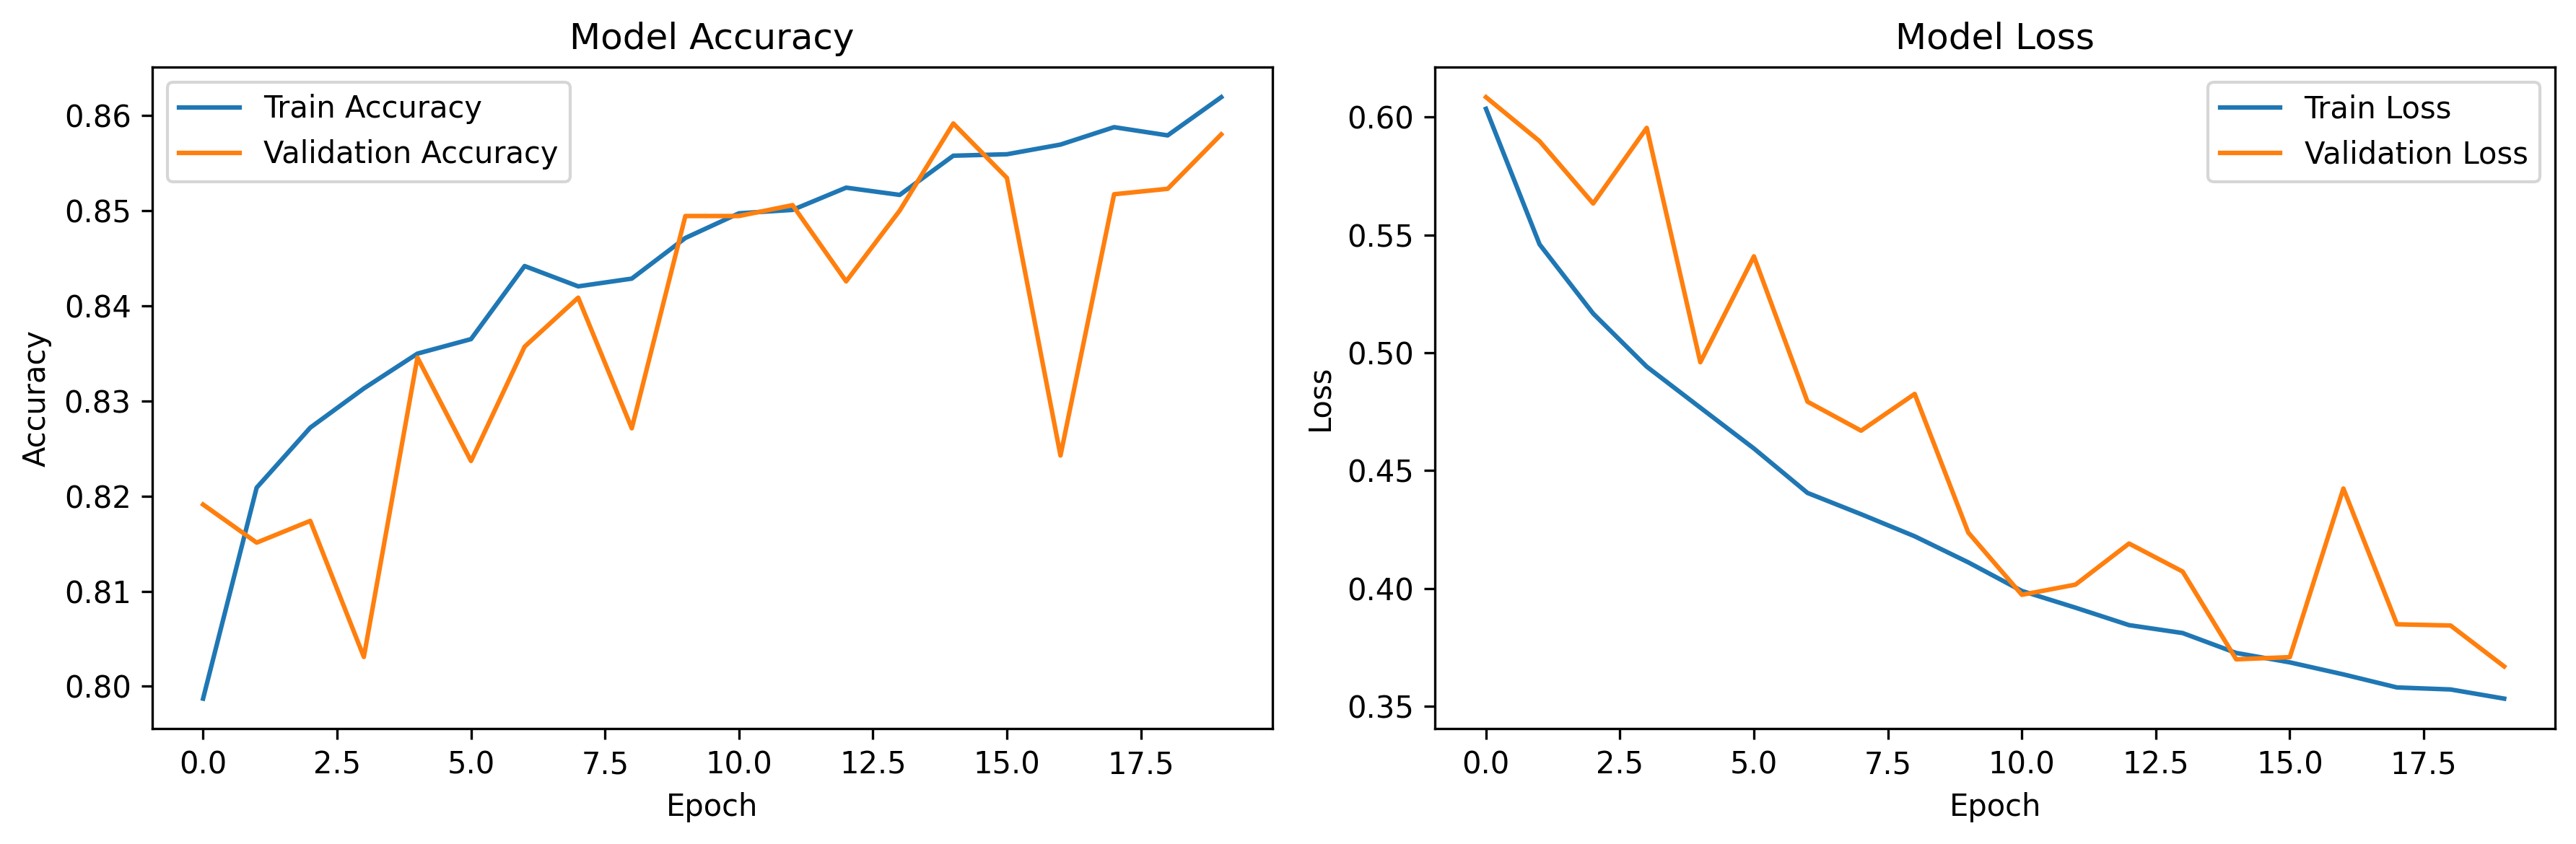

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8278 - loss: 0.4078
Test Loss: 0.3917, Test Accuracy: 0.8490


In [16]:
import matplotlib.pyplot as plt

# Save the trained model
model_save_path = '/kaggle/working/updated_ecg_mamba_model.keras'
model.save(model_save_path)
print(f"Model saved to {model_save_path}")

# Plot training history
def plot_training_history(history):
    # Plot Accuracy
    plt.figure(figsize=(12, 4),dpi=300)

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    # Set DPI to 300
    plt.tight_layout()
    plt.savefig('ECG_model.png', dpi=300)
    plt.show()

# Call the function to plot the results
plot_training_history(history)

# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(x_test_ecg, y_test_ecg)
print(f'Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}')


In [17]:
from sklearn.metrics import classification_report, roc_curve, auc, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions and metrics
y_pred_probs = model.predict(x_test_ecg)
y_pred = (y_pred_probs > 0.5).astype(int)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test_ecg, y_pred))




14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.91      0.84       191
           1       0.92      0.80      0.86       246

    accuracy                           0.85       437
   macro avg       0.85      0.86      0.85       437
weighted avg       0.86      0.85      0.85       437



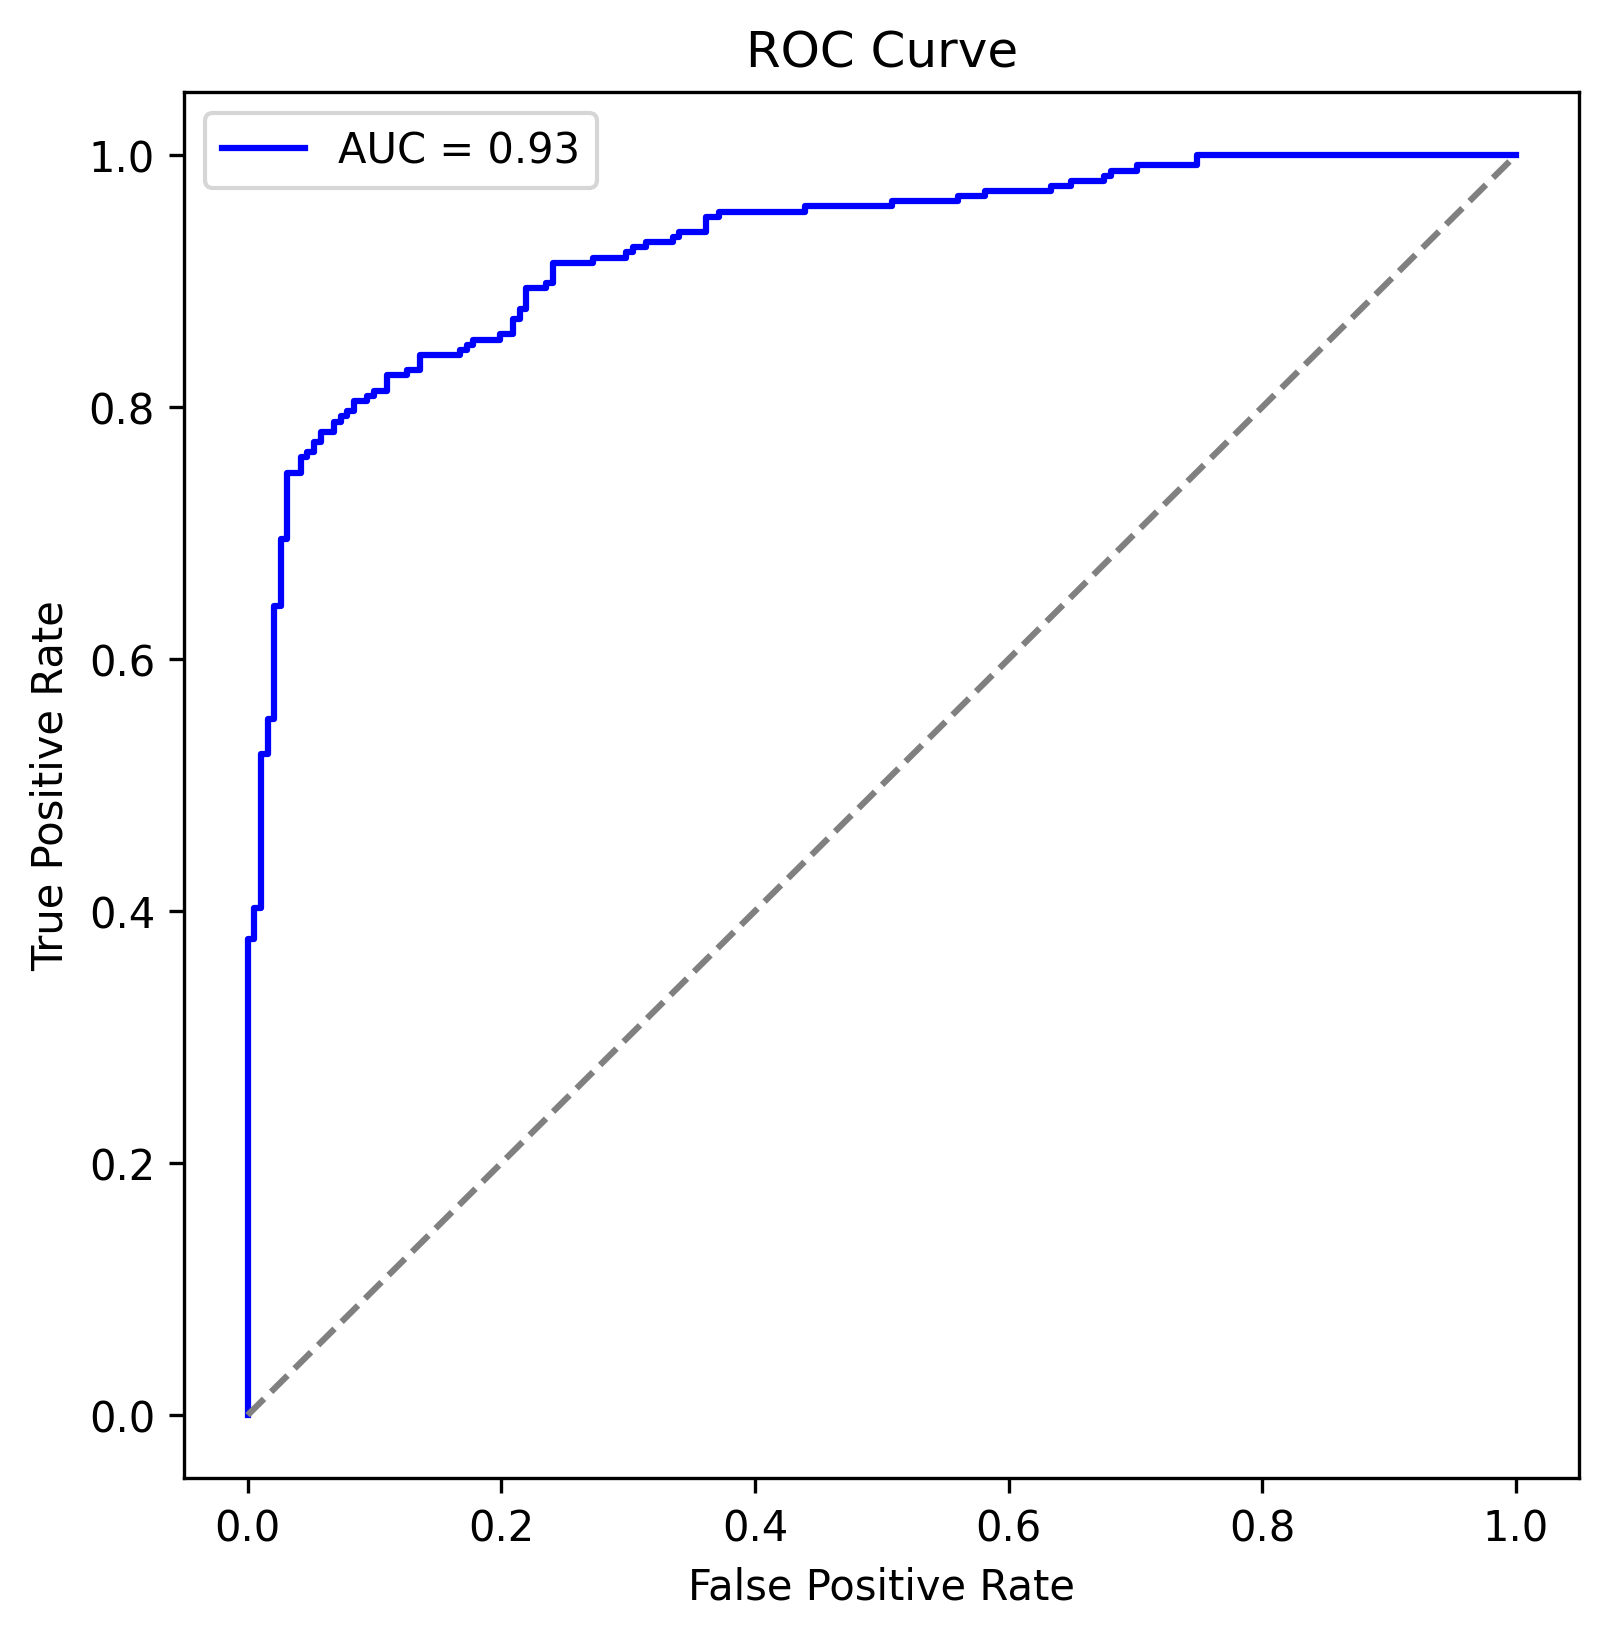

In [18]:

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_ecg, y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 6), dpi=300)
plt.plot(fpr, tpr, color='blue', label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.savefig('roc_curve.png', dpi=300)
plt.show()


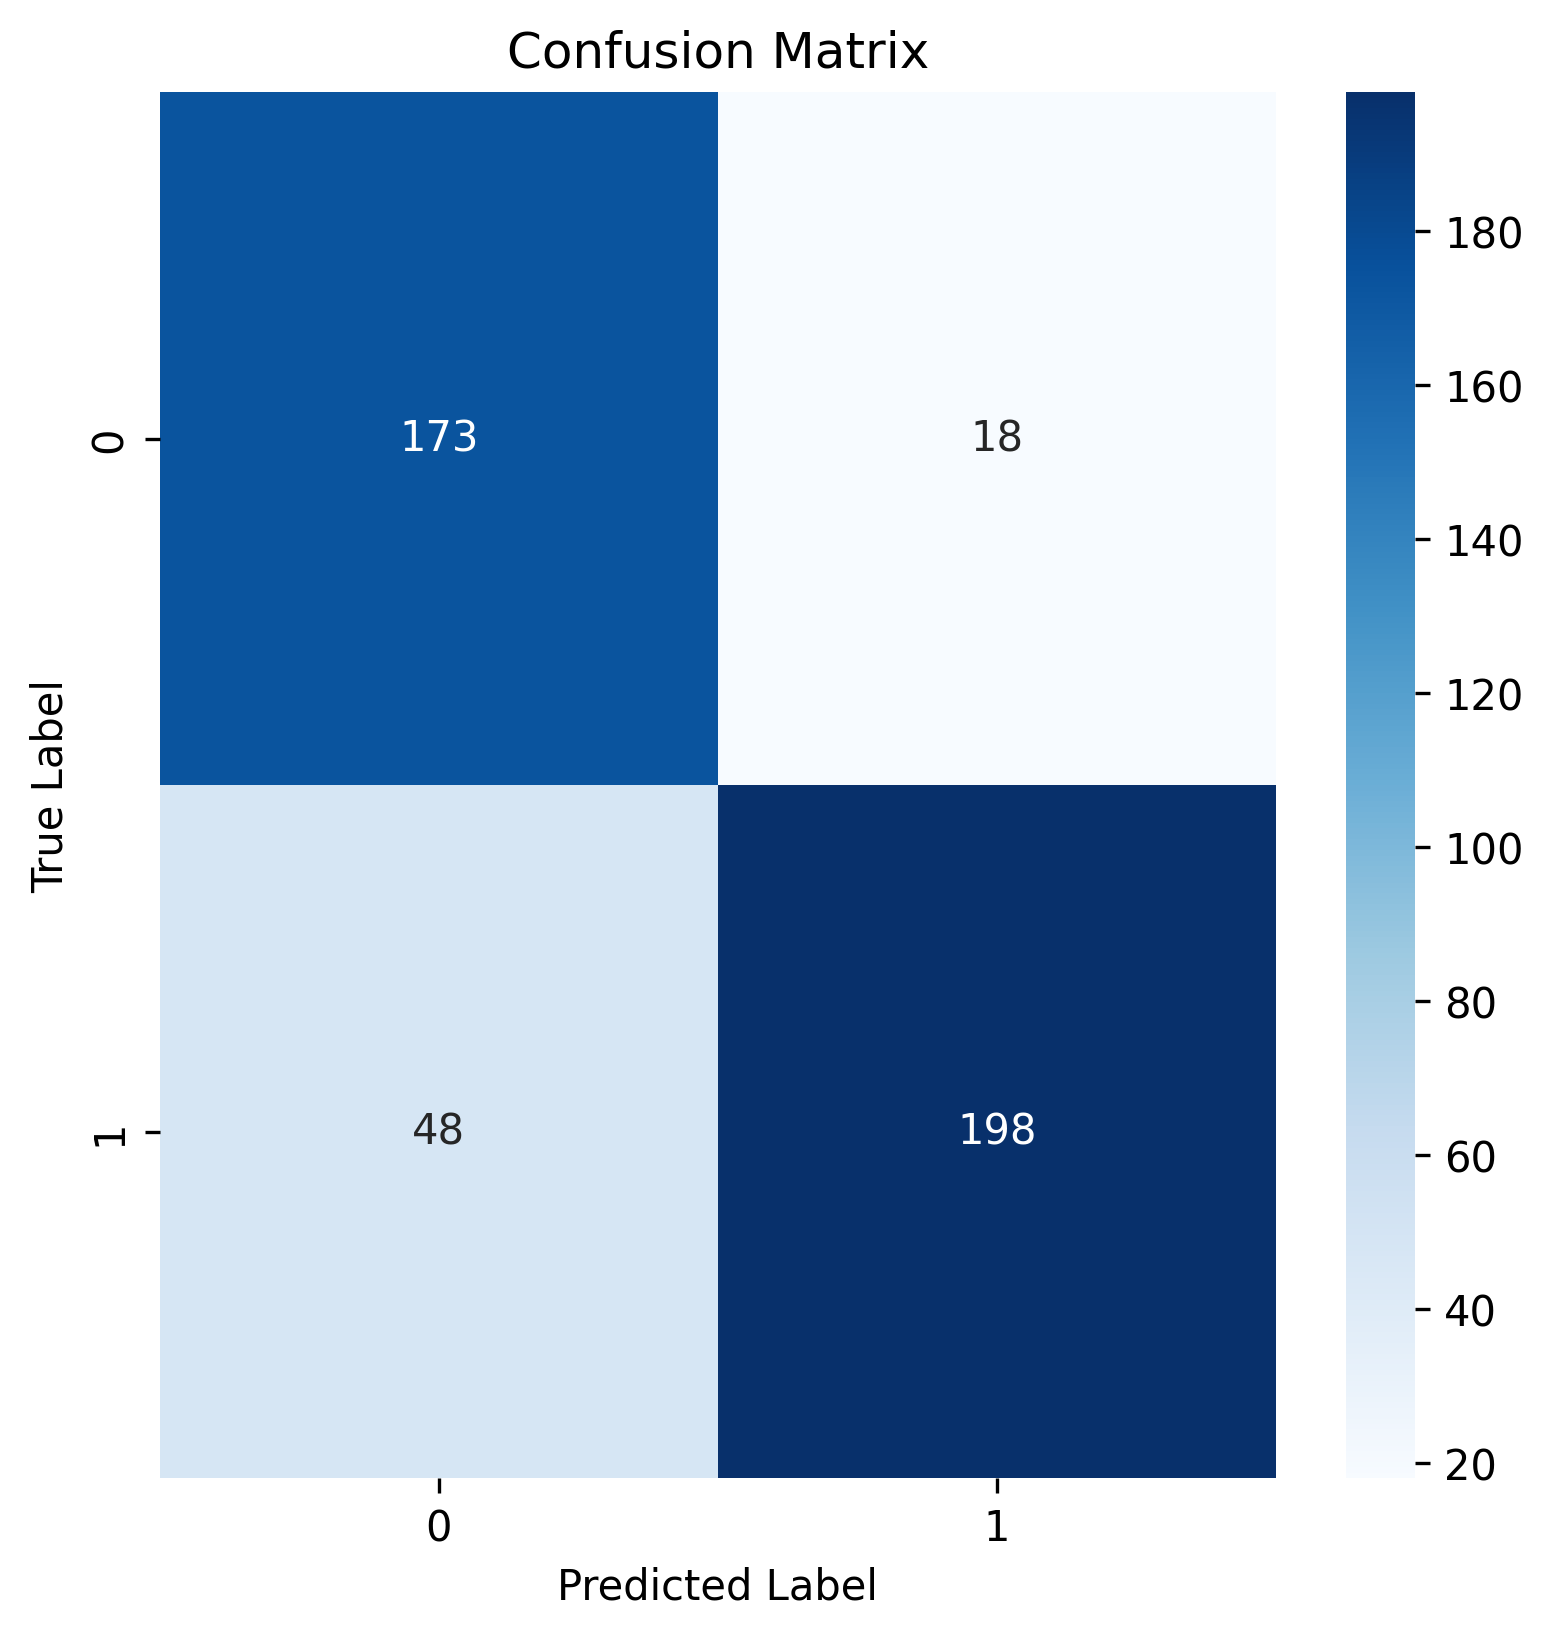

In [19]:
# Confusion Matrix
cm = confusion_matrix(y_test_ecg, y_pred)
plt.figure(figsize=(6, 6), dpi=300)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=300)
plt.show()
